In [1]:
import sqlite3
import pandas as pd
import numpy as np
import os

In [2]:
# NYC Taxi Trips
#        ↓
# Pickup Datetime
#        ↓
# Count trips every hour
#        ↓
# Hourly Time Series
#        ↓
# Previous 24 hours
#        ↓
# Transformer Encoder
#        ↓
# Transformer Decoder
#        ↓
# Predict next hour

### Load PickUp Time from all 12 Months

In [3]:
folder = r"E:\Deep Learning\DL\ML, DL, Proects\Deep Learning Projects\Transformer\Taxi Trip\2019"


data = []
for file in sorted(os.listdir(folder)):

    if file.endswith(".sqlite"):

        path = os.path.join(folder, file)
        conn = sqlite3.connect(path)
        temp = pd.read_sql(
            "SELECT tpep_pickup_datetime FROM tripdata",
            conn
        )

        data.append(temp)
        conn.close()

### Combine all months

In [4]:
df = pd.concat(data, ignore_index=True)

print("Total trips:", len(df))
print(df.head())

Total trips: 84399019
         tpep_pickup_datetime
0  2019-01-01 00:46:40.000000
1  2019-01-01 00:59:47.000000
2  2018-12-21 13:48:30.000000
3  2018-11-28 15:52:25.000000
4  2018-11-28 15:56:57.000000


In [5]:
# 4. Convert to DateTime

df["tpep_pickup_datetime"] = pd.to_datetime(
    df["tpep_pickup_datetime"]
)

In [6]:
# 5. Keep Only 2019

df = df[
    (df["tpep_pickup_datetime"] >= "2019-01-01") &
    (df["tpep_pickup_datetime"] < "2020-01-01")
]

In [7]:
# 6. Create Hourly Time Series

hourly = (
    df.set_index("tpep_pickup_datetime")
      .resample("1h")
      .size()
      .reset_index(name="trips")
)

print(hourly.head())
print(hourly.tail())
print(hourly["trips"].describe())

  tpep_pickup_datetime  trips
0  2019-01-01 00:00:00  13428
1  2019-01-01 01:00:00  15444
2  2019-01-01 02:00:00  13247
3  2019-01-01 03:00:00  10466
4  2019-01-01 04:00:00   6883
     tpep_pickup_datetime  trips
8755  2019-12-31 19:00:00  10426
8756  2019-12-31 20:00:00  12451
8757  2019-12-31 21:00:00  11073
8758  2019-12-31 22:00:00   8965
8759  2019-12-31 23:00:00   7253
count     8760.000000
mean      9634.426598
std       4817.388111
min          0.000000
25%       5542.500000
50%      11104.500000
75%      13227.250000
max      21482.000000
Name: trips, dtype: float64


In [8]:
# 7. Remove Empty Hours
# hourly = hourly[hourly["trips"] > 0].reset_index(drop=True)

In [9]:
# 8. Get only the Trip Count
values = hourly["trips"].values.reshape(-1, 1)

### Train Test Split

In [10]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(values, test_size = 0.2, shuffle = False)

### Scalling

In [11]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

In [12]:
train_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)

### Create Time Series Sequences

In [13]:
def create_data(data):

    x = []
    y = []

    for i in range(24, len(data)):
        x.append(data[i - 24: i])
        y.append(data[i])
    return np.array(x), np.array(y)

x_train, y_train = create_data(train_scaled)
x_test, y_test = create_data(test_scaled)

print("X Train:", x_train.shape)
print("Y Train:", y_train.shape)

print("X Test:", x_test.shape)
print("Y Test:", y_test.shape)

X Train: (6984, 24, 1)
Y Train: (6984, 1)
X Test: (1728, 24, 1)
Y Test: (1728, 1)


## Transformer Archeticture

In [14]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential, Model
from keras.layers import Input, MultiHeadAttention, LayerNormalization, Dense

### Enoder Archeticture

In [15]:
encoder_inputs = Input(shape=(24, 1))
encoder_attention = MultiHeadAttention(num_heads=4, key_dim=16)(encoder_inputs, encoder_inputs)

### Add & Norm

In [16]:
encoder_add = encoder_inputs + encoder_attention
encoder_norm = LayerNormalization()(encoder_add)

## FFN

In [17]:
encoder_ffn = Dense(64, activation='relu')(encoder_norm)


### Encoder Output

In [18]:
encoder_output = Dense(1)(encoder_ffn)

## Decoder Archeticture

In [19]:
decoder_inputs = Input(shape=(24, 1))
decoder_attention = MultiHeadAttention(num_heads=4, key_dim=32)(decoder_inputs, decoder_inputs, use_causal_mask = True)

### Add & Norm

In [20]:
decoder_add = decoder_inputs + decoder_attention
decoder_norm = LayerNormalization()(decoder_add)

### Cross Attention

In [21]:
cross_attention = MultiHeadAttention(num_heads=4, key_dim=32)(decoder_norm, encoder_output)

### Add & Norm

In [22]:
decoder_add2 = decoder_norm + cross_attention
decoder_norm2 = LayerNormalization()(decoder_add2)

## FFN

In [23]:
decoder_ffn = Dense(64, activation='relu')(decoder_norm2)
decoder_output = Dense(1)(decoder_ffn)

### Take Last TimeStamp

In [24]:
last_output = decoder_output[:, -1, :]

# Predict Next Hour
output = Dense(1)(last_output)

### Complete Model

In [25]:
model = Model(
    [encoder_inputs, decoder_inputs],
    output
)

### Model Compilation

In [26]:
model.compile(optimizer='adam', loss='mse', metrics=[tf.keras.metrics.R2Score(name="r2_score")])

### Model Training

In [27]:
history = model.fit([x_train, x_train], y_train, epochs=300, batch_size=32, validation_data=([x_test, x_test], y_test))

Epoch 1/300
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 41ms/step - loss: 0.1823 - r2_score: -2.6025 - val_loss: 0.0585 - val_r2_score: -0.1385
Epoch 2/300
219/219 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.0542 - r2_score: -0.0771 - val_loss: 0.0515 - val_r2_score: -0.0015
Epoch 3/300
219/219 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.0504 - r2_score: -5.1961e-04 - val_loss: 0.0515 - val_r2_score: -0.0014
Epoch 4/300
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0499 - r2_score: -3.5375e-04 - val_loss: 0.0515 - val_r2_score: -0.0016
Epoch 5/300
219/219 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - loss: 0.0494 - r2_score: -0.0035 - val_loss: 0.0515 - val_r2_score: -0.0013
Epoch 6/300
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 0.0497 - r2_score: -9.6100e-04 - val_loss: 0.0517 - val_r2_score: -0.0055
Epoch 7/300
219/219 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - loss: 0.0499 - r2_score: -0.0018 - val_loss: 0.0516 - val_r2_score: -0.0033
Epoch 8/300
219/219 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss

### R2 Score

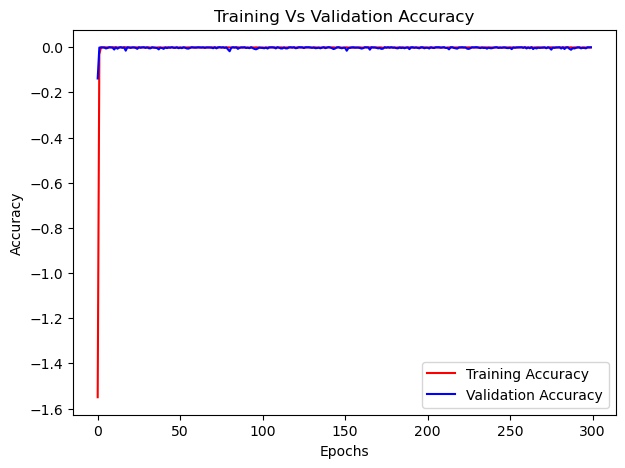

In [30]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))
plt.plot(history.history['r2_score'], label='Training Accuracy', color='red')
plt.plot(history.history['val_r2_score'], label='Validation Accuracy', color='blue')
plt.title("Training Vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Loss

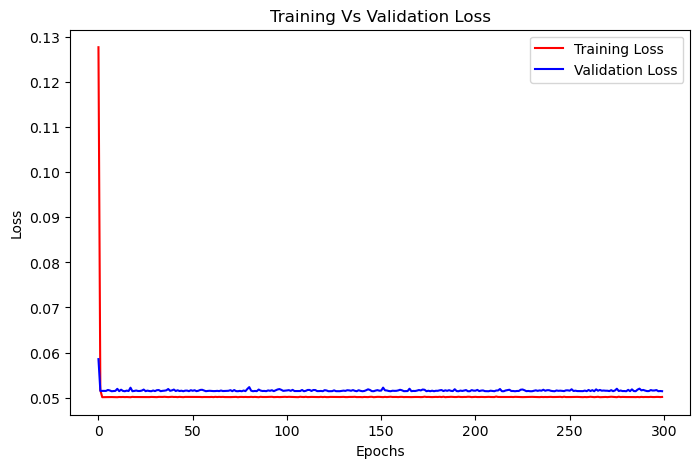

In [31]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss', color='red')
plt.plot(history.history['val_loss'], label='Validation Loss', color='blue')
plt.title("Training Vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [32]:
# Get 24 real hours
last_24 = hourly["trips"].values[-25:-1]

actual = hourly["trips"].values[-1]

# Scale
input_scaled = scaler.transform(
    last_24.reshape(-1, 1)
)

# Reshape
input_scaled = input_scaled.reshape(1, 24, 1)

# Predict
prediction = model.predict(
    [input_scaled, input_scaled]
)

# Inverse scaling
prediction = scaler.inverse_transform(prediction)

print("Actual trips:", actual)
print("Predicted trips:", round(prediction[0][0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 657ms/step
Actual trips: 7253
Predicted trips: 9535
